# TuneMatch — Data Exploration & Recommendation Model
Clean, end-to-end notebook ready for **Run All**.

## 1. Imports & Load Dataset

In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("../data/dataset.csv")
print("Raw dataset shape:", df.shape)
df.head()

Raw dataset shape: (114000, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 2. Data Cleaning & Feature Scaling

In [3]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]

# Drop missing values, index artifacts, and duplicate rows
model_df = (
    df.drop(columns=["Unnamed: 0", "Unnamed: 0.1"], errors="ignore")
    .dropna(subset=["track_name", "artists", "track_genre"] + audio_features)
    .drop_duplicates()
    .reset_index(drop=True)
)

# Ensure numeric audio features and standardize them
model_df[audio_features] = model_df[audio_features].apply(pd.to_numeric, errors="coerce")
model_df = model_df.dropna(subset=audio_features).reset_index(drop=True)

scaler = StandardScaler()
scaled_features = pd.DataFrame(
    scaler.fit_transform(model_df[audio_features]),
    columns=audio_features,
)

print("Cleaned dataset shape:", model_df.shape)
print("Scaled features shape:", scaled_features.shape)
print("Remaining duplicates:", model_df.duplicated().sum())

Cleaned dataset shape: (113549, 20)
Scaled features shape: (113549, 9)
Remaining duplicates: 0


## 3. Exploratory Data Analysis (EDA)

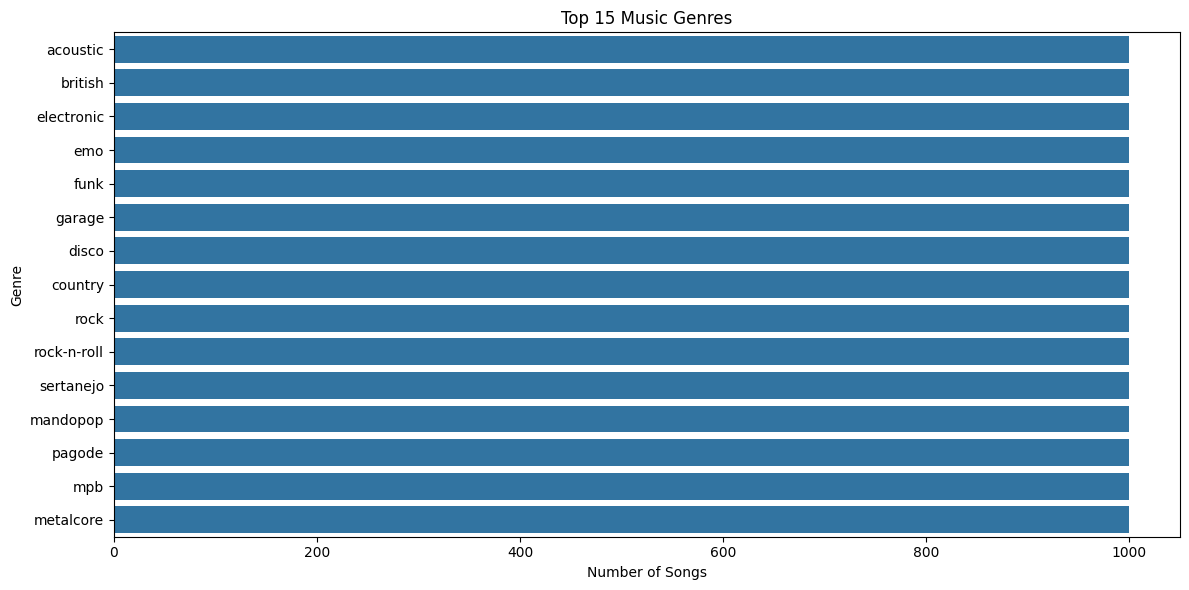

In [4]:
genre_counts = model_df["track_genre"].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("Top 15 Music Genres")
plt.xlabel("Number of Songs")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

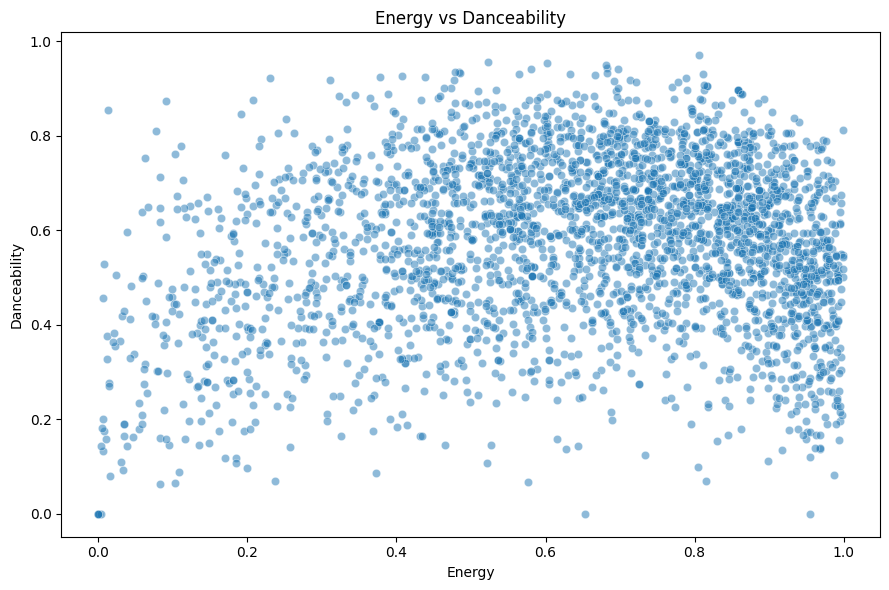

In [5]:
sample_df = model_df.sample(3000, random_state=42)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample_df, x="energy", y="danceability", alpha=0.5)
plt.title("Energy vs Danceability")
plt.xlabel("Energy")
plt.ylabel("Danceability")
plt.tight_layout()
plt.show()

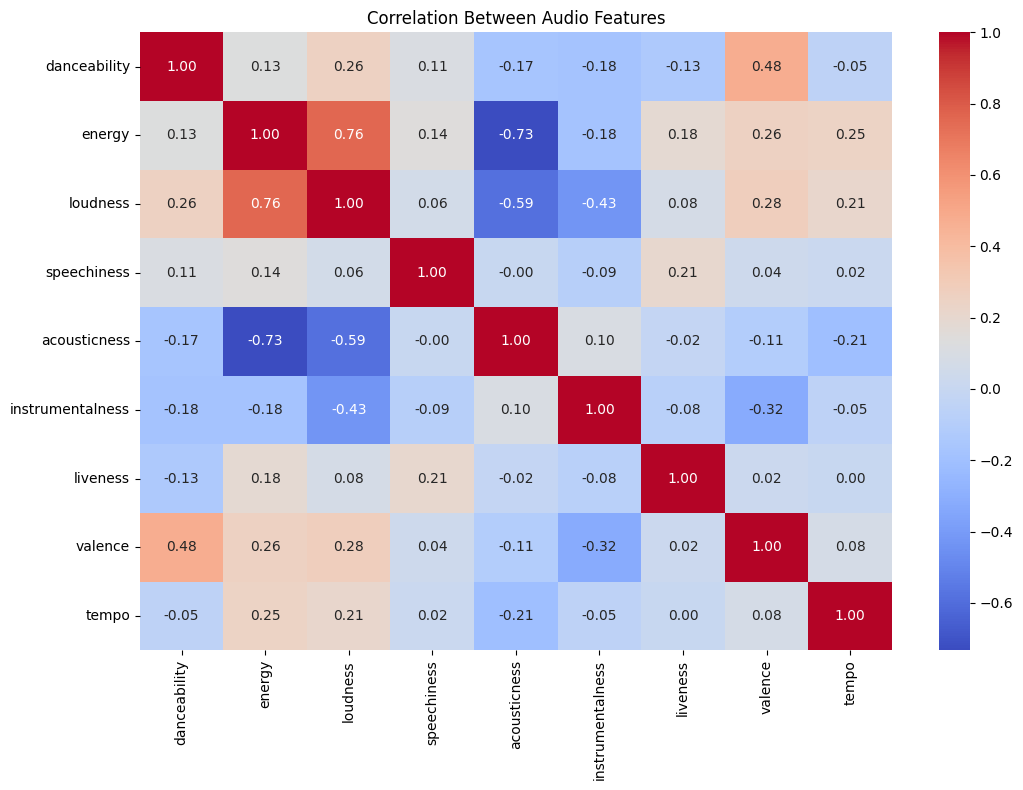

In [6]:
correlation = model_df[audio_features].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Audio Features")
plt.tight_layout()
plt.show()

## 4. TuneMatch Recommendation Engine (`recommend_songs_v5`)

In [7]:
def recommend_songs_v5(song_name, artist_name=None, n_recommendations=15):
    matches = model_df[model_df["track_name"].str.lower() == song_name.lower()]

    if artist_name:
        matches = matches[
            matches["artists"].str.contains(artist_name, case=False, na=False, regex=False)
        ]

    if matches.empty:
        print("Song not found!")
        return None

    song_index = matches.index[0]
    song = model_df.loc[song_index]
    genre = song["track_genre"]

    print(f"Selected: {song['track_name']} — {song['artists']} ({genre})")

    preferred_artist = artist_name.strip().lower() if artist_name else None
    genre_indices = model_df.index[model_df["track_genre"] == genre]

    # Filter candidates by standardized Euclidean distance
    distances = np.linalg.norm(
        scaled_features.loc[genre_indices].values - scaled_features.loc[[song_index]].values,
        axis=1,
    )
    candidate_indices = genre_indices[distances <= 2.5]

    # Rank candidates by cosine similarity + preferred artist boost
    similarities = cosine_similarity(
        scaled_features.loc[candidate_indices],
        scaled_features.loc[[song_index]],
    ).flatten()

    results = pd.DataFrame({
        "Index": candidate_indices,
        "Similarity": similarities,
        "Song": model_df.loc[candidate_indices, "track_name"].values,
        "Artist": model_df.loc[candidate_indices, "artists"].values,
        "Genre": model_df.loc[candidate_indices, "track_genre"].values,
    })

    results = results[results["Index"] != song_index].copy()
    results["Main Artist"] = results["Artist"].str.split(";").str[0].str.strip()
    results["Preferred Artist Match"] = results["Artist"].apply(
        lambda artists: (
            preferred_artist in {a.strip().lower() for a in artists.split(";")}
            if preferred_artist
            else False
        )
    )
    results["Ranking Score"] = results["Similarity"] + results["Preferred Artist Match"] * 0.10
    results = results.sort_values("Ranking Score", ascending=False)

    # Enforce artist diversity
    selected = []
    artist_counts = {}
    preferred_artist_count = 0

    for _, row in results.iterrows():
        lead_artist = row["Main Artist"].lower()
        is_preferred = row["Preferred Artist Match"]

        if is_preferred and preferred_artist_count >= 2:
            continue

        limit = 2 if (preferred_artist and lead_artist == preferred_artist) else 1
        if artist_counts.get(lead_artist, 0) >= limit:
            continue

        selected.append(row)
        artist_counts[lead_artist] = artist_counts.get(lead_artist, 0) + 1
        if is_preferred:
            preferred_artist_count += 1

        if len(selected) == n_recommendations:
            break

    final_results = pd.DataFrame(selected)
    if final_results.empty:
        print("No recommendations found!")
        return None

    final_results["Similarity (%)"] = (final_results["Similarity"] * 100).round(2)
    return final_results[["Song", "Artist", "Genre", "Similarity (%)"]].reset_index(drop=True)

## 5. Test Recommendations

In [8]:
test_songs = [
    ("Tum Hi Ho", "Arijit Singh"),
    ("Ilahi", "Arijit Singh"),
    ("O Saki Saki (From \"Batla House\")", "Neha Kakkar"),
    ("Shape of You", "Ed Sheeran"),
]

for song, artist in test_songs:
    recs = recommend_songs_v5(song, artist_name=artist, n_recommendations=15)
    if recs is not None:
        display(recs)

Selected: Tum Hi Ho — Arijit Singh (pop-film)


,Song,Artist,Genre,Similarity (%)
0,"Tum Hi Ho (From ""Aashiqui 2"")",Arijit Singh,pop-film,99.99
1,Aasan Nahin Yahan,Arijit Singh,pop-film,98.45
2,Dariya,Arko,pop-film,98.11
3,Tere Liye,Madan Mohan;Lata Mangeshkar;Roop Kumar Rathod;...,pop-film,97.25
4,Maana Ke Hum Yaar Nahin,Sachin-Jigar;Parineeti Chopra;Kausar Munir,pop-film,95.21
5,Kya Karoon?,Shankar-Ehsaan-Loy;Clinton Cerejo;Dominique Ce...,pop-film,94.97
6,Rozana,Shreya Ghoshal;Rochak Kohli,pop-film,94.46
7,"Lo Safar (From ""Baaghi 2"")",Jubin Nautiyal;Mithoon,pop-film,94.01
8,Nazm Nazm feat. Ayushmann Khurana,Ayushmann Khurrana,pop-film,93.81
9,Tenu Na Bol Pawaan,Yasser Desai;Jyotica Tangri,pop-film,93.63


Selected: Ilahi — Pritam;Arijit Singh (indian)


,Song,Artist,Genre,Similarity (%)
0,Nach Baliye,Shankar;Ehsaan;Loy;Shankar Mahadevan;Sowmya Ra...,indian,90.39
1,Tick Tick Tick,Kailash Kher;Prem Jogi;Vijay Prakash;Siddarth ...,indian,90.07
2,Jannat Jahan,Pritam;Rupam Islam,indian,88.27
3,One More Round (Free Fire Booyah Day Theme Song),KSHMR;Jeremy Oceans,indian,84.53
4,Arambath - From “Second Show”,Avial,indian,84.50
5,Agnikunjondru,Masala Coffee;Sooraj Santhosh,indian,84.17
6,Udd Gaye,Ritviz,indian,80.93
7,Khudi,The Local Train,indian,78.39
8,Doobey - Sickflip Remix,OAFF;Savera;Sickflip;Lothika;Kausar Munir,indian,76.72
9,Kosandra - Remix,Maikkis,indian,75.02


Selected: O Saki Saki (From "Batla House") — Neha Kakkar;Tulsi Kumar;B Praak;Tanishk Bagchi;Vishal-Shekhar (pop-film)


,Song,Artist,Genre,Similarity (%)
0,"Lamborghini (From ""Jai Mummy Di"")",Meet Bros.;Neha Kakkar;Jassie Gill,pop-film,84.06
1,Ishqam,Mika Singh;Ali Quli Mirza,pop-film,90.58
2,Dilbar,Neha Kakkar;Dhvani Bhanushali;Ikka,pop-film,78.84
3,Chinna Thamarai,Vijay Antony;Krishh;Suchitra,pop-film,87.42
4,"Bhaag D.K. Bose, Aandhi Aayi",Ram Sampath,pop-film,86.83
5,Mungda,Jyotica Tangri;Shaan;Subhro Ganguly;Gourov-Ros...,pop-film,85.90
6,Lut Gaye,Jubin Nautiyal;Emraan Hashmi,pop-film,85.68
7,Chikni Chameli,Ajay-Atul;Shreya Ghoshal,pop-film,85.49
8,"Halka Halka (From ""Fanney Khan"")",Sunidhi Chauhan;Divya Kumar;Amit Trivedi,pop-film,84.88
9,Born to Shine,Diljit Dosanjh,pop-film,83.83


Selected: Shape of You — Ed Sheeran (pop)


,Song,Artist,Genre,Similarity (%)
0,"Srivalli (From ""Pushpa The Rise Part - 01"")",Javed Ali;Devi Sri Prasad,pop,95.11
1,"Naah Goriye (From ""Bala"")",B Praak;Harrdy Sandhu;Swasti Mehul,pop,92.77
2,Left and Right (Feat. Jung Kook of BTS),Charlie Puth;Jung Kook;BTS,pop,92.65
3,Calm Down (with Selena Gomez),Rema;Selena Gomez,pop,91.73
4,Naah,Harrdy Sandhu,pop,91.70
5,"Mayakkama Kalakkama (From ""Thiruchitrambalam"")",Dhanush;Anirudh Ravichander,pop,90.73
6,Tauba (feat. Badshah),Payal Dev;Badshah,pop,90.44
7,There's Nothing Holdin' Me Back,Shawn Mendes,pop,90.04
8,"Coka 2.0 (From ""Liger (Telugu)"")",Jaani;Lijo George-Dj Chetas;Ram Miriyala;Geeth...,pop,89.97
9,Closer,The Chainsmokers;Halsey,pop,88.27


## 6. Export Model Artifacts for Flask App

In [9]:
website_data = Path(r"C:\Users\hssdh\Downloads\TuneMatch_Website_Starter")
website_data.mkdir(parents=True, exist_ok=True)

with open(website_data / "model_df.pkl", "wb") as f:
    pickle.dump(model_df, f)

with open(website_data / "scaled_features.pkl", "wb") as f:
    pickle.dump(scaled_features, f)

print("Model data exported successfully!")
print("Model shape:", model_df.shape)
print("Features shape:", scaled_features.shape)

Model data exported successfully!
Model shape: (113549, 20)
Features shape: (113549, 9)
